# Lab 1: Multiclass Classification with a Neural Network
## Dry beans: a full solution in simple English

**Main question:** Can a neural network find the type of a bean from 16 numbers?

I use the Dry Bean Dataset. Each row is one bean. Each input number describes its size or shape.
The answer is one of seven bean types. I use numbers from images, not the images themselves.

### How to read and run this notebook

1. Open this notebook in Jupyter or VS Code.
2. Select the Python kernel from the project **.venv**.
3. Use **Restart Kernel and Run All**. Run the cells from top to bottom.
4. Read the text before each code cell. It explains the steps.
5. Read the results and the text after the cell.

The file **data/dry_bean.csv** is included. With this file, I can run the work without the Internet.
If the file is missing, the loading cell downloads the original UCI data.
Training time depends on the computer. The notebook prints progress every 25 epochs.

### The four parts

1. **Method:** prepare the data and explain the model.
2. **Results:** run the experiments and show the numbers.
3. **Meaning of the results:** study test scores and mistakes.
4. **Conclusions:** answer all ten lab questions.

### Small word list

| Word | Simple meaning |
|---|---|
| Sample | One example: one bean |
| Feature | One input number, such as bean area |
| Label / class | The correct bean type |
| Model | A system that uses inputs to make an answer |
| Prediction | The answer from the model |
| Training | The model changes its numbers to make better answers |
| Weight | A number that controls the effect of an input |
| Bias | An extra number added inside a neuron |
| Epoch | One pass through all training examples |
| Batch | A small group of training examples |
| Loss | A number that measures prediction error; lower is better |
| Metric | A number that helps us check the model |
| Validation set | Data used to compare models during this work |
| Test set | Data used for the final check |
| Parameter | A weight or bias learned during training |
| Seed | A fixed number that helps repeat a random choice |

**Source:** [Dry Bean, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/602/dry%2Bbean%2Bdataset),
2020. DOI: [10.24432/C50S4B](https://doi.org/10.24432/C50S4B).
The dataset has a [CC BY 4.0 license](https://creativecommons.org/licenses/by/4.0/).
The source file uses the class name **DERMASON**. I keep this spelling from the data.

# Part 1. Method

## Step 1. Import the tools

I first load the Python tools.

- **NumPy** works with arrays of numbers.
- **pandas** works with tables.
- **Matplotlib** and **seaborn** draw graphs.
- **SciPy** reads the original ARFF data file.
- **scikit-learn** splits and scales data, trains the network, and checks its answers.
- **deepcopy** saves an independent copy of a model.
- **perf_counter** measures time.
- **threadpool_limits** uses one CPU thread during training. This helps make timing more consistent.

I set the seed to 42. I use 100 epochs and batches of 64 beans in every main experiment.

In [1]:
from pathlib import Path
from io import BytesIO, StringIO
from urllib.request import urlopen
from zipfile import ZipFile
from copy import deepcopy
from time import perf_counter
from importlib.metadata import version
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, log_loss, f1_score, classification_report,
    precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay,
)
from threadpoolctl import threadpool_limits

SEED = 42
EPOCHS = 100
BATCH_SIZE = 64
LEARNING_RATE = 0.001
BASELINE = (32, 16)
FEATURES_TO_PLOT = ["Area", "AspectRatio", "Compactness"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

def say(text):
    display(Markdown(text))

tools_used = pd.DataFrame({
    "Tool": ["Python", "numpy", "pandas", "matplotlib", "seaborn", "scipy", "scikit-learn"],
    "Version": [platform.python_version()] + [
        version(name) for name in
        ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "scikit-learn"]
    ],
})
display(tools_used)
print("Seed:", SEED, "| Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE)

,Tool,Version
0,Python,3.14.3
1,numpy,2.5.3
2,pandas,3.0.5
3,matplotlib,3.11.2
4,seaborn,0.13.2
5,scipy,1.18.1
6,scikit-learn,1.9.1


Seed: 42 | Epochs: 100 | Batch size: 64


**What the output means:** The table shows the software used for this run.
A fixed seed helps repeat the experiment. Small differences can still happen on other computers or software versions.
Importing these tools does not train a model.

## Step 2. Load the original data

1. Find the lab folder. I can run the notebook from the project folder or from lab1.
2. Look for the saved CSV file.
3. If needed, download the official UCI ZIP file and read its ARFF table.
4. Change class names from bytes to normal text.
5. Save the original rows as CSV. Do not clean the saved source table.
6. Show the first five rows and the table size.

A **CSV** is a text file with rows and columns. A **DataFrame** is a table in pandas.

In [2]:
current_folder = Path.cwd()
LAB_DIR = current_folder / "lab1" if (current_folder / "lab1").is_dir() else current_folder
DATA_DIR = LAB_DIR / "data"
DATA_FILE = DATA_DIR / "dry_bean.csv"
DATA_URL = "https://archive.ics.uci.edu/static/public/602/dry%2Bbean%2Bdataset.zip"

if not DATA_FILE.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with urlopen(DATA_URL, timeout=60) as response:
        archive = ZipFile(BytesIO(response.read()))
    arff_name = next(name for name in archive.namelist() if name.lower().endswith(".arff"))
    records, _ = arff.loadarff(StringIO(archive.read(arff_name).decode("utf-8")))
    downloaded = pd.DataFrame(records)
    downloaded["Class"] = downloaded["Class"].str.decode("utf-8")
    downloaded.to_csv(DATA_FILE, index=False)
    print("Downloaded and saved the UCI data.")
else:
    print("Loaded the saved data. No download was needed.")

raw_data = pd.read_csv(DATA_FILE)
display(raw_data.head())
print("Rows and columns:", raw_data.shape)
print("Input features:", raw_data.shape[1] - 1)
print("Classes:", raw_data["Class"].nunique())
assert raw_data.shape == (13611, 17), "Check that this is the original UCI table."
assert raw_data["Class"].nunique() == 7

Loaded the saved data. No download was needed.


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Rows and columns: (13611, 17)
Input features: 16
Classes: 7


**What the output means:** There are **13,611 beans**, **16 input features**, and **one Class column**.
So the table has 17 columns, but the network gets only 16 inputs.
A row is a bean; it is not a whole bean class.

## Step 3. Check missing values and repeated rows

A **missing value** is an empty place in the table. A **duplicate** is a repeated row.

1. Count missing values in each column.
2. Count rows that are exact copies of earlier rows.
3. Remove exact copies before the split.
4. Check that one feature row does not have two different labels.

The original ARFF file calls one feature **AspectRation**. I rename it to **AspectRatio**
in the working table to match the lab text. This changes only the name, not its values.

Why remove copies first? The same bean numbers could enter both train and test.
Then the final check could look too good. I keep one copy of each exact row.

In [3]:
missing_counts = raw_data.isna().sum()
duplicate_count = int(raw_data.duplicated().sum())
display(missing_counts.rename("Missing values").to_frame())
print("Repeated rows:", duplicate_count)

assert missing_counts.sum() == 0, "Missing values need a clear cleaning rule."
data = raw_data.drop_duplicates().reset_index(drop=True)
data = data.rename(columns={"AspectRation": "AspectRatio"})
feature_names = [name for name in data.columns if name != "Class"]
conflicting_labels = data.groupby(feature_names)["Class"].nunique().gt(1).sum()
assert conflicting_labels == 0, "The same inputs have different labels."
assert not data.duplicated(subset=feature_names).any()

say(
    f"**Result:** I remove **{duplicate_count}** repeated rows. "
    f"I keep **{len(data):,}** different beans. There are **no missing values** "
    "and no repeated feature rows with different labels."
)

,Missing values
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Repeated rows: 68


**Result:** I remove **68** repeated rows. I keep **13,543** different beans. There are **no missing values** and no repeated feature rows with different labels.

**What the output means:** The raw data has 68 repeated rows. The clean table has **13,543 rows**.
All later splits and experiments use this clean table. The saved CSV still keeps all original rows.
I do not fill empty cells because there are no empty cells.

## Step 4. Understand the 16 inputs

The network needs numbers. These features describe a bean's size and shape.

| Feature | Simple meaning |
|---|---|
| Area | The number of pixels inside the bean |
| Perimeter | The length of the bean's edge |
| MajorAxisLength | The long axis of the bean |
| MinorAxisLength | The short axis of the bean |
| AspectRatio | Long axis divided by short axis |
| Eccentricity | How long and thin the bean is |
| ConvexArea | The area inside a smooth outer shape around the bean |
| EquivDiameter | The diameter of a circle with the same area |
| Extent | Bean area divided by the area of its bounding box |
| Solidity | Bean area divided by ConvexArea |
| roundness | A measure of how round the bean is |
| Compactness | Circle diameter divided by the long axis |
| ShapeFactor1–ShapeFactor4 | Four extra numbers that describe the bean's shape |

A **pixel** is one small point in an image. A **ratio** is one number divided by another.
I keep the source names, except **AspectRation**, which I change to **AspectRatio** as explained above.

## Step 5. Count the classes

1. Count each bean type before and after cleaning.
2. Divide each clean count by the total to find its percentage.
3. Draw a bar chart. A taller bar means more beans.

This tells me whether all classes have a similar number of examples.

,Before cleaning,After cleaning,Share (%)
Class,,,
BARBUNYA,1322,1322,9.76
BOMBAY,522,522,3.85
CALI,1630,1630,12.04
DERMASON,3546,3546,26.18
HOROZ,1928,1860,13.73
SEKER,2027,2027,14.97
SIRA,2636,2636,19.46


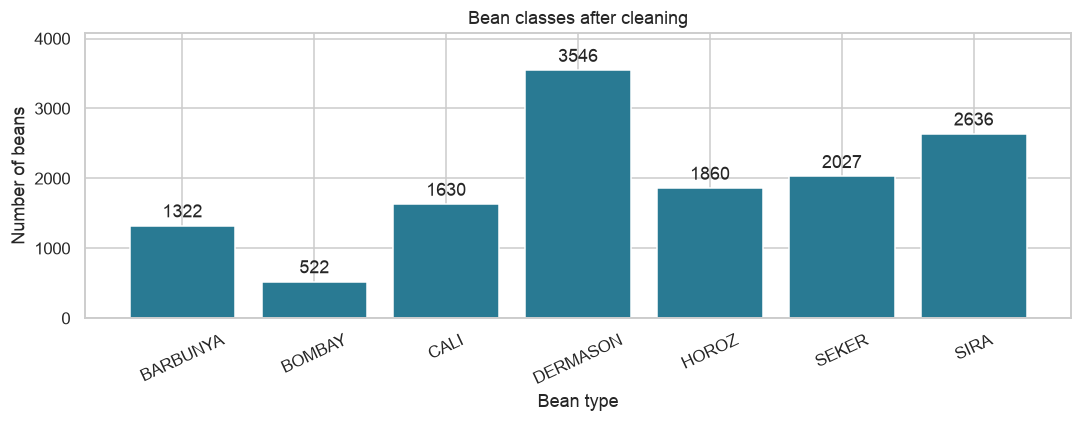

**Result:** **DERMASON** has the most beans (3,546). **BOMBAY** has the fewest (522). The largest group is about **6.8 times** the smallest group.

In [4]:
class_counts = data["Class"].value_counts().sort_index()
class_count_table = pd.DataFrame({
    "Before cleaning": raw_data["Class"].value_counts().sort_index(),
    "After cleaning": class_counts,
    "Share (%)": (100 * class_counts / len(data)).round(2),
})
display(class_count_table)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(class_counts.index, class_counts.values, color="#297a93")
ax.bar_label(bars, padding=3)
ax.set(title="Bean classes after cleaning", xlabel="Bean type", ylabel="Number of beans")
ax.set_ylim(0, class_counts.max() * 1.15)
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

say(
    f"**Result:** **{class_counts.idxmax()}** has the most beans "
    f"({class_counts.max():,}). **{class_counts.idxmin()}** has the fewest "
    f"({class_counts.min():,}). The largest group is about "
    f"**{class_counts.max() / class_counts.min():.1f} times** the smallest group."
)

**What the output means:** The classes are not equal in size.
This is called **class imbalance**. A model can get many answers right by doing well on large classes.
Later I also use **macro F1**, which gives each class the same importance.

## Step 6. Study the feature numbers

I use descriptive statistics: short numbers that describe a column.

- **count:** how many values it has.
- **mean:** the average.
- **std:** how far the values usually are from the average.
- **min / max:** the smallest / largest value.
- **25%, 50%, 75%:** points below which 25%, 50%, and 75% of values lie.
- **50%** is also called the **median**, the middle value.

I show all 16 features. Then I compare the sizes of their means.

In [5]:
statistics = data[feature_names].describe().T
display(statistics.round(4))
display(statistics.loc[FEATURES_TO_PLOT, ["mean", "std", "min", "50%", "max"]].round(4))
say(
    f"**Result:** Mean Area is **{statistics.loc['Area', 'mean']:,.2f}**, "
    f"but mean Compactness is **{statistics.loc['Compactness', 'mean']:.4f}**. "
    "These input numbers have very different sizes."
)

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000
Perimeter,13543.0,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700
MajorAxisLength,13543.0,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602
MinorAxisLength,13543.0,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985
AspectRatio,13543.0,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303
Eccentricity,13543.0,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114
ConvexArea,13543.0,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000
EquivDiameter,13543.0,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744
Extent,13543.0,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662
Solidity,13543.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


,mean,std,min,50%,max
Area,53048.4604,29392.4383,20420.0000,44580.0000,254616.0000
AspectRatio,1.5811,0.2452,1.0249,1.5499,2.4303
Compactness,0.8004,0.0615,0.6406,0.8015,0.9873


**Result:** Mean Area is **53,048.46**, but mean Compactness is **0.8004**. These input numbers have very different sizes.

**What the output means:** A large number does not always mean a more useful feature.
Area and Compactness use different scales. This is one reason to test standardization.
These statistics describe the data. They do not set the scaler: the scaler will use train data only.

## Step 7. Compare three features across classes

I choose **Area**, **AspectRatio**, and **Compactness**. They show size, length compared with width, and shape.

I draw a **box plot** for each feature:
- the line inside a box is the median;
- the box holds the middle 50% of values;
- the lines outside the box show more of the spread;
- dots show values far from the box.

Boxes at different heights can help separate classes. Boxes that overlap can make the task harder.

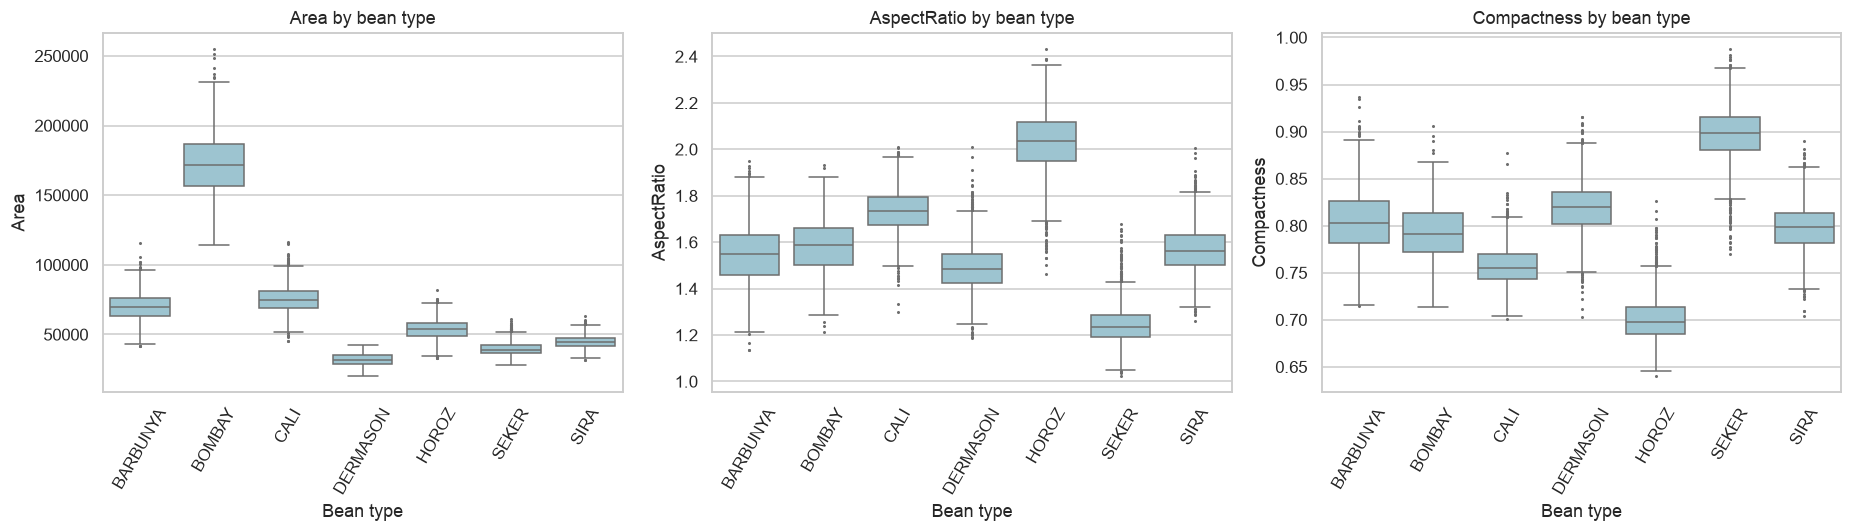

,Area,AspectRatio,Compactness
Class,,,
BARBUNYA,69582.0,1.5478,0.8024
BOMBAY,171494.5,1.5863,0.7911
CALI,74791.5,1.7339,0.7555
DERMASON,31890.0,1.4847,0.8195
HOROZ,53797.0,2.0367,0.6980
SEKER,39180.0,1.2362,0.8987
SIRA,44593.0,1.5624,0.7983


**Result:** **BOMBAY** has the largest median Area. **HOROZ** has the largest median AspectRatio. The plots also show overlap between some classes.

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, feature in zip(axes, FEATURES_TO_PLOT):
    sns.boxplot(data=data, x="Class", y=feature, order=class_counts.index,
                color="#95c8d8", fliersize=1, ax=ax)
    ax.set(title=f"{feature} by bean type", xlabel="Bean type", ylabel=feature)
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

feature_medians = data.groupby("Class")[FEATURES_TO_PLOT].median()
display(feature_medians.round(4))
say(
    f"**Result:** **{feature_medians['Area'].idxmax()}** has the largest median Area. "
    f"**{feature_medians['AspectRatio'].idxmax()}** has the largest median AspectRatio. "
    "The plots also show overlap between some classes."
)

**What the output means:** One feature does not give a clear border for every class.
The model can combine all 16 features. These three features were chosen to explain size and shape,
not from test scores. I do not change the feature set after looking at test errors.

## Step 8. Separate inputs and labels

1. Put the 16 input columns in **X**.
2. Put the correct bean names in the target.
3. Use **LabelEncoder** to change the seven names into numbers 0 to 6.
4. Show the name for each number.

The numbers are IDs. Class 6 is not larger or better than class 0.
The list of seven possible names is known for this task. Encoding these names does not learn feature statistics.

In [7]:
X = data[feature_names].copy()
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data["Class"])
class_names = label_encoder.classes_
class_ids = np.arange(len(class_names))

display(pd.DataFrame({"Class ID": class_ids, "Bean type": class_names}))
print("X shape:", X.shape)
print("y shape:", y.shape)
assert X.shape[1] == 16
assert np.isfinite(X.to_numpy()).all()

,Class ID,Bean type
0,0,BARBUNYA
1,1,BOMBAY
2,2,CALI
3,3,DERMASON
4,4,HOROZ
5,5,SEKER
6,6,SIRA


X shape: (13543, 16)
y shape: (13543,)


**What the output means:** X has one row per bean and 16 columns.
y has one correct answer per row. The Class column is not inside X.
If I gave Class to the network as an input, I would give it the answer.

## Step 9. Make three separate sets

I use **70% train**, **15% validation**, and **15% test**.

1. Keep 70% for train and 30% for a temporary group.
2. Split the temporary group into two equal parts.
3. Use **stratify** to keep class shares close to the full data.
4. Use seed 42 to repeat the split.
5. Check that no row ID is in two sets.

**Train** changes weights and biases.
**Validation** helps choose an epoch and an architecture.
**Test** gives the final check after these choices.

If I use test scores to choose a model, I learn from the test set.
Then it is no longer a fair check on unseen data.

In [8]:
all_indices = np.arange(len(data))
train_idx, temporary_idx = train_test_split(
    all_indices, test_size=0.30, random_state=SEED, stratify=y
)
val_idx, test_idx = train_test_split(
    temporary_idx, test_size=0.50, random_state=SEED, stratify=y[temporary_idx]
)

X_train, X_val, X_test = X.iloc[train_idx], X.iloc[val_idx], X.iloc[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(data)
for labels in [y_train, y_val, y_test]:
    assert np.array_equal(np.unique(labels), class_ids)

split_table = pd.DataFrame({
    "Set": ["Train", "Validation", "Test"],
    "Beans": [len(train_idx), len(val_idx), len(test_idx)],
})
split_table["Share (%)"] = 100 * split_table["Beans"] / len(data)
display(split_table.round(2))

split_classes = pd.DataFrame({
    "Train": np.bincount(y_train, minlength=7),
    "Validation": np.bincount(y_val, minlength=7),
    "Test": np.bincount(y_test, minlength=7),
}, index=class_names)
display(split_classes)
print("All three sets are separate. Each set has all seven classes.")

,Set,Beans,Share (%)
0,Train,9480,70.0
1,Validation,2031,15.0
2,Test,2032,15.0


,Train,Validation,Test
BARBUNYA,925,199,198
BOMBAY,366,78,78
CALI,1141,244,245
DERMASON,2482,532,532
HOROZ,1302,279,279
SEKER,1419,304,304
SIRA,1845,395,396


All three sets are separate. Each set has all seven classes.


**What the output means:** The percentages can differ a little from 70/15/15 because a row cannot be cut in half.
The split uses row IDs. Since exact copies were removed before the split, copied feature rows do not cross the sets.
The test features stay unused until the final model is fixed.

## Step 10. Standardize the features

Standardization puts features on a more similar scale.

For one feature:

$$z = \frac{x-\mu}{\sigma}$$

- $x$ is the original value.
- $\mu$ is the **training** mean.
- $\sigma$ is the **training** standard deviation.
- $z$ is the new value.

I first subtract the training mean. Then I divide by the training standard deviation.
A value near the mean becomes close to 0. A value one standard deviation above the mean becomes close to 1.

I use **fit_transform** on train. It learns the mean and standard deviation and changes the numbers.
I use only **transform** on validation. It uses the same saved numbers.
I do not scale the test set yet.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_train_raw = X_train.to_numpy()
X_val_raw = X_val.to_numpy()

assert scaler.n_samples_seen_ == len(X_train)
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_train_scaled.std(axis=0), 1, atol=1e-10)

area_col = feature_names.index("Area")
first_area = float(X_train.iloc[0]["Area"])
area_mean = float(scaler.mean_[area_col])
area_std = float(scaler.scale_[area_col])
first_area_scaled = float(X_train_scaled[0, area_col])

display(pd.DataFrame({
    "Feature": feature_names,
    "Train mean before": scaler.mean_,
    "Train std before": scaler.scale_,
    "Train mean after": X_train_scaled.mean(axis=0),
    "Train std after": X_train_scaled.std(axis=0),
}).round(4))

say(
    f"**One real example:** Area = {first_area:,.2f}. "
    f"The train mean is {area_mean:,.2f}. The train standard deviation is {area_std:,.2f}.\n\n"
    f"New Area = ({first_area:,.2f} − {area_mean:,.2f}) / {area_std:,.2f} "
    f"= **{first_area_scaled:.4f}**."
)

,Feature,Train mean before,Train std before,Train mean after,Train std after
0,Area,52987.8885,29341.3188,0.0,1.0
1,Perimeter,854.3407,214.2560,-0.0,1.0
2,MajorAxisLength,319.6686,85.6143,-0.0,1.0
3,MinorAxisLength,202.2954,45.0235,-0.0,1.0
4,AspectRatio,1.5805,0.2448,-0.0,1.0
5,Eccentricity,0.7502,0.0917,0.0,1.0
6,ConvexArea,53706.7483,29788.5606,-0.0,1.0
7,EquivDiameter,252.9003,59.2260,0.0,1.0
8,Extent,0.7501,0.0486,0.0,1.0
9,Solidity,0.9871,0.0047,-0.0,1.0


**One real example:** Area = 45,684.00. The train mean is 52,987.89. The train standard deviation is 29,341.32.

New Area = (45,684.00 − 52,987.89) / 29,341.32 = **-0.2489**.

**What the output means:** The new train means are close to 0, and train standard deviations are close to 1.
Validation means do not have to be exactly 0. That set has different beans.
Using validation or test means to fit the scaler would be **data leakage**: information from a checking set
would enter the training process.

StandardScaler uses the population standard deviation (ddof=0).
The pandas statistics table uses a sample standard deviation (ddof=1), so the values can differ slightly.

## Step 11. Design and explain the baseline network

My baseline is **16 → 32 → 16 → 7**. It is different from the example in the lab.

| Choice | My setting | Why I use it |
|---|---|---|
| Input | 16 features | There are 16 numbers for one bean |
| Hidden layer 1 | 32 neurons | It can learn several combinations of the inputs |
| Hidden layer 2 | 16 neurons | It combines the first layer's patterns |
| Hidden activation | ReLU | It adds a nonlinear step and is simple to calculate |
| Output | 7 neurons with Softmax | I need a probability for each class |
| Loss | Multiclass cross-entropy | It checks the probability given to the true class |
| Optimizer | Adam | It changes the weights with an adaptive step for each weight |
| Learning rate | 0.001 | A small starting step is a useful first choice |
| Batch size | 64 | Each update uses a small group of beans |
| Epochs | 100 | I can watch learning over a fixed number of passes |
| Extra regularization | None, alpha=0 | I keep this experiment simple and compare the same loss |
| Best saved model | Lowest validation loss | Later epochs can fit train data too closely |

These are starting choices, not proof that this is the best possible network.
The architecture experiment checks a smaller and a larger network.

### 11.1 What one neuron does

A neuron calculates a weighted sum:

$$z = x_1w_1 + x_2w_2 + \cdots + x_nw_n + b.$$

First, multiply each input $x$ by its weight $w$. Next, add the results. Last, add bias $b$.

For example, with two inputs:

$$z = 1(0.6) + 2(-0.2) + 0.1 = 0.6 - 0.4 + 0.1 = 0.3.$$

**ReLU** means:

$$\mathrm{ReLU}(z)=\max(0,z).$$

It keeps a positive number and changes a negative number to 0.
Here, ReLU(0.3) = 0.3. For z = -0.3, ReLU(-0.3) = 0.
Without a nonlinear step, many dense layers would still behave like one linear map.

### 11.2 Why Softmax is useful

The last layer makes seven scores, $z_1,\ldots,z_7$. Softmax changes them into probabilities:

$$p_k=\frac{e^{z_k}}{\sum_{j=1}^{7} e^{z_j}}.$$

First, calculate the exponential of each score. Next, add all seven results.
Then divide each result by that total. The seven probabilities add up to 1.
The largest probability gives the predicted class.

For example, a true class probability of 0.8 means the network gives that class 80% of the total.
This is the model's estimate, not a promise that it is right.

### 11.3 What cross-entropy means

For one bean with true class $c$:

$$L=-\log(p_c).$$

The log is the natural logarithm. If the true class has probability 0.8, the loss is about 0.223.
If it has probability 0.1, the loss is about 2.303. A confident wrong answer has a high loss.
For a set of beans, I take the mean of these losses.

### 11.4 How learning works

1. Send a batch of inputs through the network. This is the **forward pass**.
2. Compare its probabilities with the correct classes and find the loss.
3. Use **backpropagation** to find how each weight affects the loss.
4. Adam uses these values to change the weights and biases.
5. Repeat for the next batch. One full pass through train is one epoch.

The update values are called **gradients**. Backpropagation finds them;
the optimizer uses them. The library does these calculations for us.

## Step 12. Count the trainable parameters

A layer with $a$ inputs and $b$ neurons has:

$$a \times b + b$$

parameters: $a \times b$ weights and $b$ biases.

For my baseline:
- first hidden layer: $16 \times 32 + 32 = 544$;
- second hidden layer: $32 \times 16 + 16 = 528$;
- output layer: $16 \times 7 + 7 = 119$.

The total is $544 + 528 + 119 = 1191$.

The input values are not trainable parameters.

In [10]:
def parameter_count(hidden_layers):
    layer_sizes = (16,) + tuple(hidden_layers) + (7,)
    return sum(a * b + b for a, b in zip(layer_sizes[:-1], layer_sizes[1:]))

baseline_layers = pd.DataFrame({
    "Layer": ["Hidden 1", "Hidden 2", "Output"],
    "Inputs": [16, 32, 16],
    "Neurons": [32, 16, 7],
})
baseline_layers["Weights"] = baseline_layers["Inputs"] * baseline_layers["Neurons"]
baseline_layers["Biases"] = baseline_layers["Neurons"]
baseline_layers["Total"] = baseline_layers["Weights"] + baseline_layers["Biases"]
display(baseline_layers)
print("Total trainable parameters:", parameter_count(BASELINE))
assert parameter_count(BASELINE) == 1191

,Layer,Inputs,Neurons,Weights,Biases,Total
0,Hidden 1,16,32,512,32,544
1,Hidden 2,32,16,512,16,528
2,Output,16,7,112,7,119


Total trainable parameters: 1191


**What the output means:** The baseline learns **1,191 parameters**.
More parameters can help learn more patterns, but they can also fit training details that do not help with new beans.

## Step 13. Make one clear training function

I use the same function in every experiment.

1. Make a new MLP with the chosen hidden layers.
2. Call **partial_fit** once for each epoch. It makes one pass through the training data.
   The model and Adam's state stay in memory between calls.
3. At the end of the epoch, predict train and validation probabilities.
4. Calculate the mean cross-entropy and accuracy for both sets.
5. Save a deep copy when validation loss becomes lower.
6. Return the best saved model and all 100 rows of history.

I calculate both losses in the same way with **log_loss** at the end of each epoch.
I do not compare a changing within-epoch loss with an end-of-epoch loss.
The function has no test-set argument.

I also make a small function that creates one row for a result table.
The displayed time includes training, epoch checks, and saving the best model.

In [11]:
def train_network(hidden_layers, train_X, train_y, validation_X, validation_y, name):
    model = MLPClassifier(
        hidden_layer_sizes=tuple(hidden_layers),
        activation="relu",
        solver="adam",
        alpha=0.0,
        batch_size=BATCH_SIZE,
        learning_rate_init=LEARNING_RATE,
        early_stopping=False,
        shuffle=True,
        random_state=SEED,
    )
    history_rows = []
    best_loss = np.inf
    best_epoch = None
    best_model = None
    start = perf_counter()

    with threadpool_limits(limits=1):
        for epoch in range(1, EPOCHS + 1):
            model.partial_fit(train_X, train_y, classes=class_ids)
            train_probabilities = model.predict_proba(train_X)
            val_probabilities = model.predict_proba(validation_X)
            train_predictions = model.classes_[train_probabilities.argmax(axis=1)]
            val_predictions = model.classes_[val_probabilities.argmax(axis=1)]

            row = {
                "Epoch": epoch,
                "Train loss": log_loss(train_y, train_probabilities, labels=class_ids),
                "Validation loss": log_loss(validation_y, val_probabilities, labels=class_ids),
                "Train accuracy": accuracy_score(train_y, train_predictions),
                "Validation accuracy": accuracy_score(validation_y, val_predictions),
            }
            assert np.isfinite(list(row.values())).all()
            history_rows.append(row)

            if row["Validation loss"] < best_loss:
                best_loss = row["Validation loss"]
                best_epoch = epoch
                best_model = deepcopy(model)

            if epoch % 25 == 0:
                print(
                    f"{name}: epoch {epoch}/{EPOCHS}, "
                    f"validation loss={row['Validation loss']:.4f}, "
                    f"validation accuracy={row['Validation accuracy']:.4f}",
                    flush=True,
                )

    seconds = perf_counter() - start
    with threadpool_limits(limits=1):
        probabilities = best_model.predict_proba(validation_X)
    predictions = best_model.classes_[probabilities.argmax(axis=1)]
    actual_parameters = sum(a.size for a in best_model.coefs_ + best_model.intercepts_)
    assert actual_parameters == parameter_count(hidden_layers)
    assert best_model.out_activation_ == "softmax"
    assert np.array_equal(best_model.classes_, class_ids)

    return {
        "name": name,
        "hidden_layers": tuple(hidden_layers),
        "model": best_model,
        "history": pd.DataFrame(history_rows),
        "best_epoch": best_epoch,
        "seconds": seconds,
        "parameters": actual_parameters,
        "validation_loss": log_loss(validation_y, probabilities, labels=class_ids),
        "validation_accuracy": accuracy_score(validation_y, predictions),
        "validation_macro_f1": f1_score(
            validation_y, predictions, labels=class_ids, average="macro", zero_division=0
        ),
    }

def result_row(run):
    best_row = run["history"].iloc[run["best_epoch"] - 1]
    return {
        "Model": run["name"],
        "Architecture": " → ".join(map(str, (16,) + run["hidden_layers"] + (7,))),
        "Parameters": run["parameters"],
        "Train loss": best_row["Train loss"],
        "Validation loss": run["validation_loss"],
        "Validation accuracy": run["validation_accuracy"],
        "Macro F1": run["validation_macro_f1"],
        "Best epoch": run["best_epoch"],
        "Epochs run": EPOCHS,
        "Seconds": run["seconds"],
    }

print("The training and result-table functions are ready.")

The training and result-table functions are ready.


**What the output means:** This cell defines the process. It does not train a network yet.
I always run 100 epochs, but the saved model may come from an earlier epoch.
A **deep copy** keeps its old weights safe while the working model continues to learn.

I use fixed settings and one seed so the experiments are easy to compare.
One seed is a limit of this small lab: another split or seed may give a different ranking.

# Part 2. Results

## Step 14. Train with and without scaling

I train the same baseline twice:
1. with the original feature values;
2. with standardized feature values.

The split, seed, architecture, optimizer, batch size, and number of epochs stay the same.
Only scaling changes. I use validation results to compare the two runs.

In [12]:
unscaled_run = train_network(
    BASELINE, X_train_raw, y_train, X_val_raw, y_val, "Baseline: no scaling"
)
scaled_run = train_network(
    BASELINE, X_train_scaled, y_train, X_val_scaled, y_val, "Baseline: scaled"
)
scaling_table = pd.DataFrame([result_row(unscaled_run), result_row(scaled_run)])
display(scaling_table.round(4))

scaling_gain = scaled_run["validation_accuracy"] - unscaled_run["validation_accuracy"]
say(
    f"**Result:** Without scaling, validation accuracy is "
    f"**{unscaled_run['validation_accuracy']:.2%}**. With scaling, it is "
    f"**{scaled_run['validation_accuracy']:.2%}**. "
    f"The change is **{100 * scaling_gain:+.2f} percentage points**.\n\n"
    f"Validation loss changes from **{unscaled_run['validation_loss']:.4f}** "
    f"to **{scaled_run['validation_loss']:.4f}**. "
    "These scores use each run's saved best epoch."
)

Baseline: no scaling: epoch 25/100, validation loss=15.0930, validation accuracy=0.2708


Baseline: no scaling: epoch 50/100, validation loss=12.1123, validation accuracy=0.4481


Baseline: no scaling: epoch 75/100, validation loss=5.0130, validation accuracy=0.6524


Baseline: no scaling: epoch 100/100, validation loss=6.0706, validation accuracy=0.6342


Baseline: scaled: epoch 25/100, validation loss=0.2093, validation accuracy=0.9247


Baseline: scaled: epoch 50/100, validation loss=0.2086, validation accuracy=0.9232


Baseline: scaled: epoch 75/100, validation loss=0.2085, validation accuracy=0.9202


Baseline: scaled: epoch 100/100, validation loss=0.2108, validation accuracy=0.9222


,Model,Architecture,Parameters,Train loss,Validation loss,Validation accuracy,Macro F1,Best epoch,Epochs run,Seconds
0,Baseline: no scaling,16 → 32 → 16 → 7,1191,2.510,2.5174,0.6327,0.5837,61,100,2.1854
1,Baseline: scaled,16 → 32 → 16 → 7,1191,0.169,0.2082,0.9227,0.9328,57,100,2.1498


**Result:** Without scaling, validation accuracy is **63.27%**. With scaling, it is **92.27%**. The change is **+29.00 percentage points**.

Validation loss changes from **2.5174** to **0.2082**. These scores use each run's saved best epoch.

**What the output means:** The table compares two trained networks, not two different train/test splits.
A **percentage point** is a direct difference between two percentages: from 80% to 85% is 5 percentage points.

Large raw inputs can make very large neuron scores. They can also make weight updates hard to balance.
Scaling gives the features more similar sizes. It does not make all features equally useful.

## Step 15. Compare learning speed and curves

I draw loss and accuracy for both runs.

- The horizontal axis is the epoch.
- A lower loss is better.
- A higher accuracy is better.
- The dashed vertical line marks the saved epoch.
- Each loss panel has its own vertical scale so I can see its changes.

I also report the first epoch that reaches 90% validation accuracy.
This is one shared target for both runs. If a model never reaches it, I say so.
The time is measured on this computer and includes the checks after each epoch.

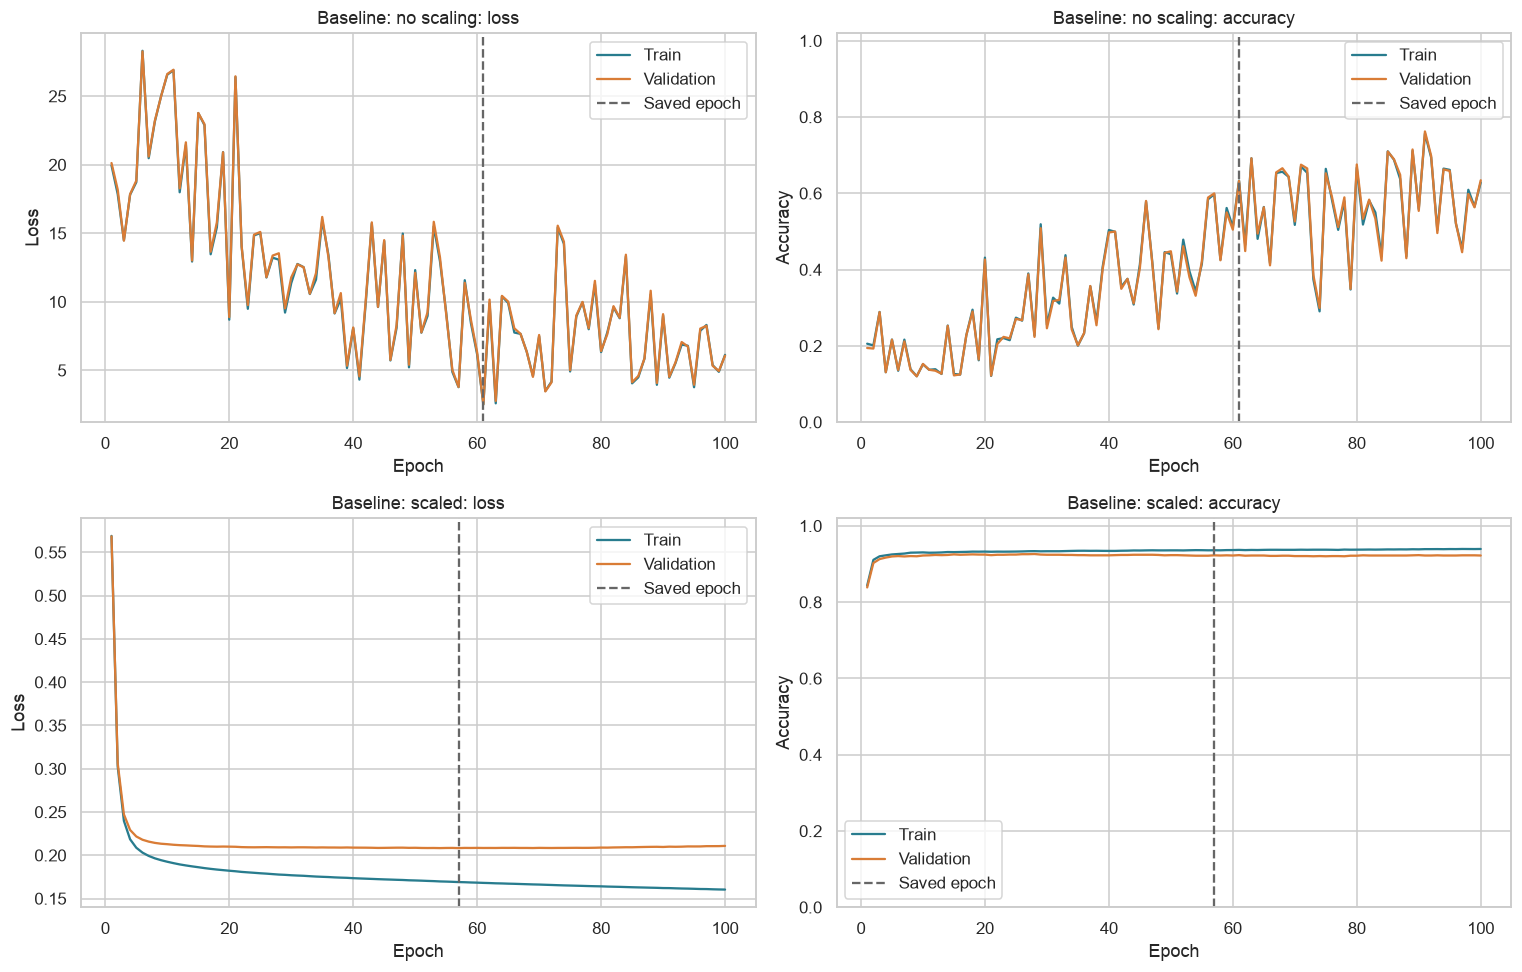

,Model,First epoch at 90% validation accuracy,Best validation-loss epoch,Total seconds,Seconds per epoch
0,Baseline: no scaling,Not reached,61,2.19,0.022
1,Baseline: scaled,2,57,2.15,0.021


**Baseline: no scaling:** first epoch at 90% validation accuracy: **Not reached**; lowest validation loss at epoch **61**; total time **2.19 seconds**.

**Baseline: scaled:** first epoch at 90% validation accuracy: **2**; lowest validation loss at epoch **57**; total time **2.15 seconds**.

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
speed_rows = []
for row_index, run in enumerate([unscaled_run, scaled_run]):
    history = run["history"]
    for column, metric in enumerate(["loss", "accuracy"]):
        ax = axes[row_index, column]
        ax.plot(history["Epoch"], history[f"Train {metric}"], label="Train", color="#287c8e")
        ax.plot(history["Epoch"], history[f"Validation {metric}"], label="Validation", color="#d97c36")
        ax.axvline(run["best_epoch"], color="#666666", linestyle="--", label="Saved epoch")
        ax.set(title=f"{run['name']}: {metric}", xlabel="Epoch", ylabel=metric.title())
        if metric == "accuracy":
            ax.set_ylim(0, 1.02)
        ax.legend()
    reached = history.loc[history["Validation accuracy"] >= 0.90, "Epoch"]
    speed_rows.append({
        "Model": run["name"],
        "First epoch at 90% validation accuracy": int(reached.iloc[0]) if len(reached) else "Not reached",
        "Best validation-loss epoch": run["best_epoch"],
        "Total seconds": round(run["seconds"], 2),
        "Seconds per epoch": round(run["seconds"] / EPOCHS, 3),
    })
plt.tight_layout()
plt.show()
speed_table = pd.DataFrame(speed_rows)
display(speed_table)

for row in speed_rows:
    say(
        f"**{row['Model']}:** first epoch at 90% validation accuracy: "
        f"**{row['First epoch at 90% validation accuracy']}**; "
        f"lowest validation loss at epoch **{row['Best validation-loss epoch']}**; "
        f"total time **{row['Total seconds']:.2f} seconds**."
    )

**What the output means:** **Convergence** means the changes become small as training continues.
The curves show this more clearly than one final score.
An early best epoch alone does not prove faster useful learning: a weak model can stop improving early.
That is why I also show a shared 90% target and the full curves.
Time can change with computer load, even when accuracy stays the same.

## Step 16. Check the fit of the scaled baseline

- **Underfitting:** the model does not learn enough; train and validation scores are both weak.
- **Good fit:** train and validation scores are good and fairly close.
- **Overfitting:** train results improve, but validation results stop improving or get worse.

I compare the saved epoch with epoch 100. I show loss and accuracy for both.
I also compare the saved model with a simple guess: always choose the largest training class.
This guess is only a reference; it is not another neural network.

In [14]:
baseline_history = scaled_run["history"]
saved_baseline_row = baseline_history.iloc[scaled_run["best_epoch"] - 1]
last_baseline_row = baseline_history.iloc[-1]
fit_table = pd.DataFrame([saved_baseline_row, last_baseline_row],
                         index=["Saved epoch", "Last epoch"])
display(fit_table.round(4))

majority_class = np.bincount(y_train).argmax()
majority_val_accuracy = float(np.mean(y_val == majority_class))
baseline_gap = saved_baseline_row["Train accuracy"] - saved_baseline_row["Validation accuracy"]

say(
    f"**Result:** At the saved epoch, train accuracy is "
    f"**{saved_baseline_row['Train accuracy']:.2%}** and validation accuracy is "
    f"**{saved_baseline_row['Validation accuracy']:.2%}**. The train-minus-validation gap "
    f"is **{100 * baseline_gap:.2f} percentage points**. Always choosing "
    f"**{class_names[majority_class]}** gives **{majority_val_accuracy:.2%}** validation accuracy."
)

if last_baseline_row["Validation loss"] > saved_baseline_row["Validation loss"] * 1.05:
    say(
        f"Validation loss rises from **{saved_baseline_row['Validation loss']:.4f}** "
        f"at the saved epoch to **{last_baseline_row['Validation loss']:.4f}** at epoch 100. "
        "The later epochs show a sign of overfitting. I keep the earlier saved model."
    )
else:
    say(
        "The last validation loss is close to the best value. "
        "This comparison does not show a large rise in validation loss at the end."
    )

if saved_baseline_row["Validation accuracy"] > majority_val_accuracy + 0.30 and abs(baseline_gap) < 0.05:
    say(
        "**Fit at the saved epoch:** The model learns much more than the simple guess, "
        "and train and validation accuracy are close. This supports a useful fit. "
        "It does not mean that every bean is easy to classify."
    )
else:
    say(
        "**Fit at the saved epoch:** Read the train and validation scores together with the curves. "
        "A score gap alone cannot prove the cause of an error."
    )

,Epoch,Train loss,Validation loss,Train accuracy,Validation accuracy
Saved epoch,57.0,0.1690,0.2082,0.9360,0.9227
Last epoch,100.0,0.1603,0.2108,0.9393,0.9222


**Result:** At the saved epoch, train accuracy is **93.60%** and validation accuracy is **92.27%**. The train-minus-validation gap is **1.33 percentage points**. Always choosing **DERMASON** gives **26.19%** validation accuracy.

The last validation loss is close to the best value. This comparison does not show a large rise in validation loss at the end.

**Fit at the saved epoch:** The model learns much more than the simple guess, and train and validation accuracy are close. This supports a useful fit. It does not mean that every bean is easy to classify.

**What the output means:** A saved model and the model after the last epoch can have different quality.
Validation loss is sensitive to confident wrong answers. It may rise even when accuracy changes only a little.
The fit check uses validation data, not test data.

## Step 17. Choose three architectures

I use standardized data for all three networks.

| Model | Architecture | Reason |
|---|---|---|
| Small | 16 → 24 → 7 | One small hidden layer: a simple starting point |
| Baseline | 16 → 32 → 16 → 7 | Two layers: learn and combine patterns |
| Large | 16 → 96 → 48 → 24 → 7 | More neurons and one more layer: test if extra size helps |

The models use the same data, ReLU, Adam, learning rate, batch size, seed, and 100 epochs.
I reuse the scaled baseline run because it already has exactly these settings.

For each architecture, I first save the epoch with the lowest validation loss.
Then I compare those saved models using **validation macro F1**.
Macro F1 is the mean of the seven class F1 scores, so each class has equal weight.
If scores are exactly equal, I choose the model with fewer parameters.

### Train and compare the architectures

I train the small and large networks, add the existing baseline results, and sort the table.
The first row is my chosen architecture.
All scores in this table come from validation data.

In [15]:
small_run = train_network(
    (24,), X_train_scaled, y_train, X_val_scaled, y_val, "Small"
)
large_run = train_network(
    (96, 48, 24), X_train_scaled, y_train, X_val_scaled, y_val, "Large"
)
architecture_runs = {"Small": small_run, "Baseline": scaled_run, "Large": large_run}
architecture_rows = []
for name, run in architecture_runs.items():
    row = result_row(run)
    row["Model"] = name
    architecture_rows.append(row)

architecture_table = pd.DataFrame(architecture_rows).sort_values(
    ["Macro F1", "Parameters", "Model"], ascending=[False, True, True]
).reset_index(drop=True)
display(architecture_table.round(4))

selected_name = architecture_table.iloc[0]["Model"]
selected_run = architecture_runs[selected_name]
selected_hidden_layers = selected_run["hidden_layers"]
say(
    f"**Choice:** I choose **{selected_name}**, with architecture "
    f"**{architecture_table.iloc[0]['Architecture']}**. "
    f"Its validation macro F1 is **{selected_run['validation_macro_f1']:.4f}** "
    f"and its saved epoch is **{selected_run['best_epoch']}**. "
    "The choice is now fixed before any test prediction."
)

Small: epoch 25/100, validation loss=0.2123, validation accuracy=0.9207


Small: epoch 50/100, validation loss=0.2079, validation accuracy=0.9286


Small: epoch 75/100, validation loss=0.2066, validation accuracy=0.9276


Small: epoch 100/100, validation loss=0.2065, validation accuracy=0.9281


Large: epoch 25/100, validation loss=0.2100, validation accuracy=0.9237


Large: epoch 50/100, validation loss=0.2173, validation accuracy=0.9237


Large: epoch 75/100, validation loss=0.2278, validation accuracy=0.9252


Large: epoch 100/100, validation loss=0.2387, validation accuracy=0.9247


,Model,Architecture,Parameters,Train loss,Validation loss,Validation accuracy,Macro F1,Best epoch,Epochs run,Seconds
0,Small,16 → 24 → 7,583,0.1725,0.2063,0.9276,0.9375,82,100,1.6624
1,Baseline,16 → 32 → 16 → 7,1191,0.1690,0.2082,0.9227,0.9328,57,100,2.1498
2,Large,16 → 96 → 48 → 24 → 7,7639,0.1678,0.2085,0.9212,0.9312,18,100,3.3878


**Choice:** I choose **Small**, with architecture **16 → 24 → 7**. Its validation macro F1 is **0.9375** and its saved epoch is **82**. The choice is now fixed before any test prediction.

**What the output means:** Parameters measure model size; they do not measure quality.
The best epoch can be different for each network, even though each run uses 100 epochs.
The table uses validation results for selection. Test results do not choose the winner.

### Compare architecture curves

I plot validation loss and validation accuracy for all three networks.
Then I check whether macro F1 rises at every step from the small to the large model.
I describe only what this run shows.

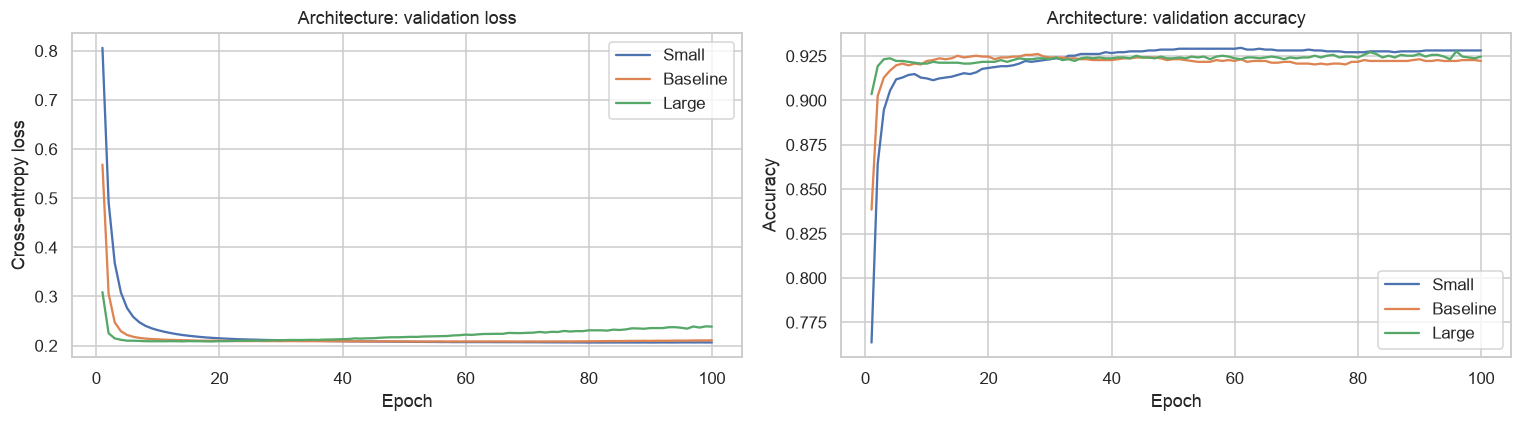

**Result:** A larger network is not always better in this run. At least one increase in size does not improve validation macro F1.

The small model has **583** parameters; the baseline has **1,191**; the large model has **7,639**.

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, run in architecture_runs.items():
    history = run["history"]
    axes[0].plot(history["Epoch"], history["Validation loss"], label=name)
    axes[1].plot(history["Epoch"], history["Validation accuracy"], label=name)
axes[0].set(title="Architecture: validation loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Architecture: validation accuracy", xlabel="Epoch", ylabel="Accuracy")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

size_order = architecture_table.sort_values("Parameters")
size_scores = size_order["Macro F1"].to_numpy()
larger_always_better = bool(np.all(np.diff(size_scores) > 0))
if larger_always_better:
    size_conclusion = (
        "In these three runs, each larger network has a higher validation macro F1. "
        "This result does not mean a larger network will always be better."
    )
else:
    size_conclusion = (
        "A larger network is not always better in this run. "
        "At least one increase in size does not improve validation macro F1."
    )
say("**Result:** " + size_conclusion)
say(
    f"The small model has **{small_run['parameters']:,}** parameters; "
    f"the baseline has **{scaled_run['parameters']:,}**; "
    f"the large model has **{large_run['parameters']:,}**."
)

**What the output means:** A larger model has more possible patterns to learn.
It can also need more time or fit details that do not help with other beans.
This experiment compares three choices with one seed. It does not search every possible architecture.

## Step 18. Creative experiment: how much training data is needed?

I use the chosen architecture with **20%, 40%, 60%, 80%, and 100%** of the training set.

1. Shuffle the training row positions separately inside each class with seed 42.
2. Take the first 20%, then 40%, and so on from each class.
3. Keep earlier rows inside the next larger set. These are **nested** subsets.
4. Fit a new scaler on each subset only.
5. Train for 100 epochs with the same settings and the same validation set.
6. Save the lowest-validation-loss epoch and compare validation results.

The class shares stay close to the full training set. Rounding can make the actual percentage a little different.
At 100%, I reuse the selected full-train run. Its data and settings are already exactly the same.
The experiment studies data size. It does not change the final model choice.

In [17]:
fractions = [0.20, 0.40, 0.60, 0.80, 1.00]
rng = np.random.default_rng(SEED)
class_pools = {
    class_id: rng.permutation(np.flatnonzero(y_train == class_id))
    for class_id in class_ids
}
subset_positions = {}
subset_runs = {}
subset_scalers = {}
size_rows = []

for fraction in fractions:
    if fraction == 1.0:
        positions = np.arange(len(y_train))
    else:
        positions = np.sort(np.concatenate([
            pool[:max(1, int(np.floor(fraction * len(pool))))]
            for pool in class_pools.values()
        ]))
    subset_positions[fraction] = positions
    assert np.array_equal(np.unique(y_train[positions]), class_ids)

    if fraction == 1.0:
        subset_scaler = scaler
        run = selected_run
    else:
        subset_scaler = StandardScaler()
        subset_train = subset_scaler.fit_transform(X_train.iloc[positions])
        subset_validation = subset_scaler.transform(X_val)
        run = train_network(
            selected_hidden_layers, subset_train, y_train[positions],
            subset_validation, y_val, f"Train size: {fraction:.0%}",
        )

    assert subset_scaler.n_samples_seen_ == len(positions)
    subset_scalers[fraction] = subset_scaler
    subset_runs[fraction] = run
    size_rows.append({
        "Requested train share (%)": int(fraction * 100),
        "Actual train share (%)": 100 * len(positions) / len(y_train),
        "Training beans": len(positions),
        "Validation accuracy": run["validation_accuracy"],
        "Validation macro F1": run["validation_macro_f1"],
        "Validation loss": run["validation_loss"],
        "Best epoch": run["best_epoch"],
        "Seconds": run["seconds"],
    })

for smaller, larger in zip(fractions[:-1], fractions[1:]):
    assert set(subset_positions[smaller]).issubset(subset_positions[larger])

size_table = pd.DataFrame(size_rows)
display(size_table.round(4))
subset_class_table = pd.DataFrame({
    f"{fraction:.0%}": np.bincount(y_train[subset_positions[fraction]], minlength=7)
    for fraction in fractions
}, index=class_names)
display(subset_class_table)
print("The subsets are nested. All have seven classes.")

Train size: 20%: epoch 25/100, validation loss=0.2757, validation accuracy=0.9124


Train size: 20%: epoch 50/100, validation loss=0.2369, validation accuracy=0.9099


Train size: 20%: epoch 75/100, validation loss=0.2322, validation accuracy=0.9138


Train size: 20%: epoch 100/100, validation loss=0.2316, validation accuracy=0.9129


Train size: 40%: epoch 25/100, validation loss=0.2279, validation accuracy=0.9104


...

Train size: 80%: epoch 75/100, validation loss=0.2096, validation accuracy=0.9301


Train size: 80%: epoch 100/100, validation loss=0.2079, validation accuracy=0.9281


,Requested train share (%),Actual train share (%),Training beans,Validation accuracy,Validation macro F1,Validation loss,Best epoch,Seconds
0,20,19.9789,1894,0.9129,0.9223,0.2316,100,0.5264
1,40,39.9684,3789,0.9237,0.9325,0.2125,87,0.8085
2,60,59.9789,5686,0.9286,0.9385,0.2079,99,1.0817
3,80,79.9684,7581,0.9281,0.9372,0.2079,100,1.3722
4,100,100.0000,9480,0.9276,0.9375,0.2063,82,1.6624


,20%,40%,60%,80%,100%
BARBUNYA,185,370,555,740,925
BOMBAY,73,146,219,292,366
CALI,228,456,684,912,1141
DERMASON,496,992,1489,1985,2482
HOROZ,260,520,781,1041,1302
SEKER,283,567,851,1135,1419
SIRA,369,738,1107,1476,1845


The subsets are nested. All have seven classes.


**What the output means:** Only training data size changes in this experiment.
The validation beans stay the same. Each scaler learns only from its own training subset.
The 100% row reuses a measured run; its time is that run's time, not the time needed to copy its result.

The same number of epochs does not mean the same number of weight updates.
A larger set has more batches per epoch. This is a limit of this comparison.

### Plot and explain the data-size result

I draw accuracy and macro F1 against the number of training beans.
I also draw validation loss. The scores are from each run's saved epoch.
Then I compare 20% with 100% and find the best observed fraction.

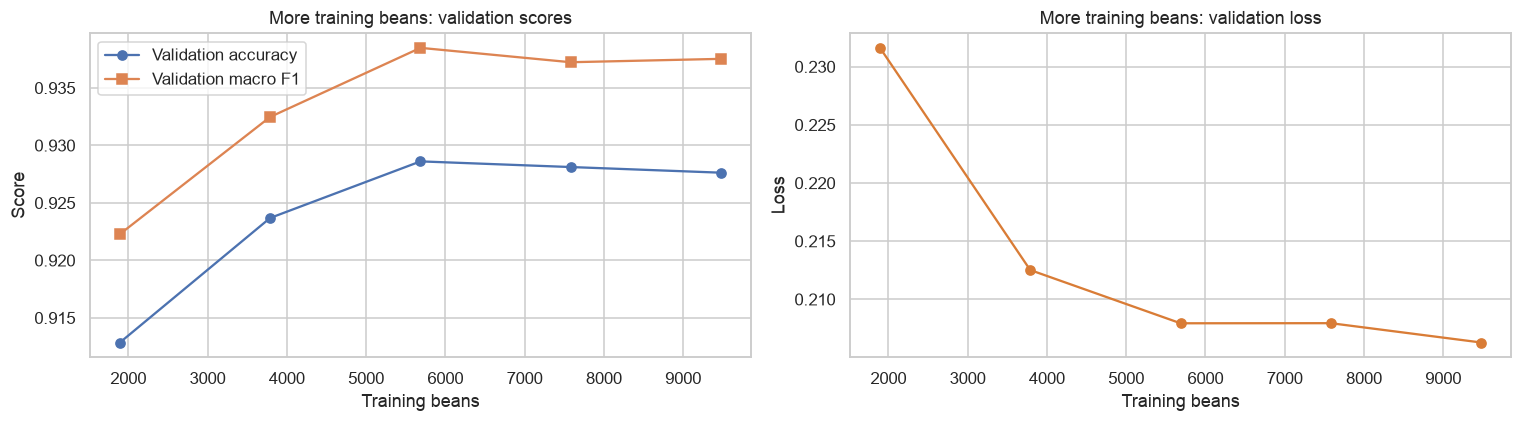

**Result:** At 20%, I use **1,894** beans and get macro F1 **0.9223**. At 100%, I use **9,480** beans and get **0.9375**. The change is **+0.0152**.

The highest observed macro F1 is **0.9385**, at **60%** of train.

Macro F1 does not increase at every step. More data does not give a better score in every single run.

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(size_table["Training beans"], size_table["Validation accuracy"],
             marker="o", label="Validation accuracy")
axes[0].plot(size_table["Training beans"], size_table["Validation macro F1"],
             marker="s", label="Validation macro F1")
axes[0].set(title="More training beans: validation scores", xlabel="Training beans", ylabel="Score")
axes[0].legend()
axes[1].plot(size_table["Training beans"], size_table["Validation loss"],
             marker="o", color="#d97c36")
axes[1].set(title="More training beans: validation loss", xlabel="Training beans", ylabel="Loss")
plt.tight_layout()
plt.show()

first_size = size_table.iloc[0]
last_size = size_table.iloc[-1]
best_size = size_table.loc[size_table["Validation macro F1"].idxmax()]
data_size_gain = last_size["Validation macro F1"] - first_size["Validation macro F1"]
size_is_monotonic = bool(np.all(np.diff(size_table["Validation macro F1"]) >= 0))

say(
    f"**Result:** At 20%, I use **{int(first_size['Training beans']):,}** beans and get "
    f"macro F1 **{first_size['Validation macro F1']:.4f}**. "
    f"At 100%, I use **{int(last_size['Training beans']):,}** beans and get "
    f"**{last_size['Validation macro F1']:.4f}**. The change is **{data_size_gain:+.4f}**.\n\n"
    f"The highest observed macro F1 is **{best_size['Validation macro F1']:.4f}**, "
    f"at **{int(best_size['Requested train share (%)'])}%** of train."
)
say(
    "Macro F1 increases or stays the same at each step."
    if size_is_monotonic else
    "Macro F1 does not increase at every step. More data does not give a better score in every single run."
)

**What the output means:** More training examples can show the model more types of beans.
Small differences may also come from the chosen examples and the training process.
This one run cannot prove the smallest amount of data needed for every situation.
I keep the already selected full-training model for the final test.

# Part 3. Meaning of the results

## Step 19. Freeze the model and open the test set

The architecture and the saved epoch are already chosen.
I keep the scaler from the full training set. I do not retrain or tune anything after this point.

1. Use the training scaler to transform test features.
2. Get seven probabilities for each test bean.
3. Check that the probabilities are finite, lie between 0 and 1, and sum to 1.
4. Choose the class with the largest probability.
5. Use these saved predictions for every test table and graph below.

I also show the first test bean as a clear example of Softmax and class choice.

In [19]:
final_model = selected_run["model"]
final_scaler = scaler
X_test_scaled = final_scaler.transform(X_test)

with threadpool_limits(limits=1):
    test_probabilities = final_model.predict_proba(X_test_scaled)
test_predictions = final_model.classes_[test_probabilities.argmax(axis=1)]

assert test_probabilities.shape == (len(y_test), 7)
assert np.isfinite(test_probabilities).all()
assert np.all((test_probabilities >= 0) & (test_probabilities <= 1))
assert np.allclose(test_probabilities.sum(axis=1), 1.0, atol=1e-10)

first_prediction_table = pd.DataFrame({
    "Class ID": class_ids,
    "Bean type": class_names,
    "Probability": test_probabilities[0],
})
display(first_prediction_table.round(6))
say(
    f"**One test bean:** Its true class is **{class_names[y_test[0]]}**. "
    f"The largest probability is **{test_probabilities[0].max():.2%}**, "
    f"so the model predicts **{class_names[test_predictions[0]]}**. "
    f"The seven probabilities add up to **{test_probabilities[0].sum():.6f}**."
)

,Class ID,Bean type,Probability
0,0,BARBUNYA,0.000000
1,1,BOMBAY,0.000000
2,2,CALI,0.000002
3,3,DERMASON,0.995211
4,4,HOROZ,0.000256
5,5,SEKER,0.001554
6,6,SIRA,0.002976


**One test bean:** Its true class is **DERMASON**. The largest probability is **99.52%**, so the model predicts **DERMASON**. The seven probabilities add up to **1.000000**.

**What the output means:** The output is a distribution over all seven classes.
A high probability can still be wrong. The first bean is just an example; it cannot measure overall quality.
I now use all test beans to calculate the final metrics.

## Step 20. Understand the metrics before reading the scores

### Accuracy

$$\mathrm{Accuracy}=\frac{\text{correct answers}}{\text{all answers}}.$$

For example, 90 correct answers out of 100 give accuracy 0.90, or 90%.

### One class against all other classes

For one chosen class:
- **TP (true positive):** it is this class, and the model says this class.
- **FP (false positive):** it is another class, but the model says this class.
- **FN (false negative):** it is this class, but the model says another class.

$$\mathrm{Precision}=\frac{TP}{TP+FP}.$$

Precision asks: of all beans the model calls this class, how many are really this class?

$$\mathrm{Recall}=\frac{TP}{TP+FN}.$$

Recall asks: of all real beans in this class, how many does the model find?

$$F1=\frac{2 \times \mathrm{Precision} \times \mathrm{Recall}}
{\mathrm{Precision}+\mathrm{Recall}}.$$

F1 combines precision and recall. A high value needs both to be good.

### Macro and weighted averages

**Macro precision**, **macro recall**, and **macro F1** are the means of the seven class scores.
Each class has equal importance.
Macro F1 is the average of seven F1 values; it is not F1 calculated from macro precision and macro recall.

A **weighted average** gives more importance to a class with more beans.
**Support** is the number of true beans in a class.
I report both averages, but macro F1 is my main class-balanced score.

### Calculate final test scores

I count correct answers, calculate accuracy, and make a report for each class.
I also show macro and weighted precision, recall, and F1.
All scores here use only the fixed model's test predictions.

In [20]:
test_accuracy = accuracy_score(y_test, test_predictions)
correct_count = int(np.sum(y_test == test_predictions))
test_loss = log_loss(y_test, test_probabilities, labels=class_ids)

test_report = classification_report(
    y_test, test_predictions, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0,
)
per_class_report = pd.DataFrame(test_report).T.loc[class_names].copy()
per_class_report["support"] = per_class_report["support"].astype(int)
display(per_class_report.round(4))

averages = []
for average in ["macro", "weighted"]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, test_predictions, labels=class_ids, average=average, zero_division=0
    )
    averages.append({"Average": average, "Precision": precision, "Recall": recall, "F1": f1})
average_table = pd.DataFrame(averages)
display(average_table.round(4))

test_macro_f1 = float(test_report["macro avg"]["f1-score"])
best_f1_class = per_class_report["f1-score"].idxmax()
lowest_f1_class = per_class_report["f1-score"].idxmin()
say(
    f"**Accuracy:** {correct_count:,} / {len(y_test):,} = **{test_accuracy:.4f}** "
    f"(**{test_accuracy:.2%}**).\n\n"
    f"**Macro F1:** **{test_macro_f1:.4f}**. **Test cross-entropy:** **{test_loss:.4f}**.\n\n"
    f"**{best_f1_class}** has the highest class F1 "
    f"(**{per_class_report.loc[best_f1_class, 'f1-score']:.4f}**). "
    f"**{lowest_f1_class}** has the lowest "
    f"(**{per_class_report.loc[lowest_f1_class, 'f1-score']:.4f}**)."
)

,precision,recall,f1-score,support
BARBUNYA,0.9436,0.9293,0.9364,198
BOMBAY,1.0000,1.0000,1.0000,78
CALI,0.9312,0.9388,0.9350,245
DERMASON,0.9208,0.8966,0.9086,532
HOROZ,0.9498,0.9498,0.9498,279
SEKER,0.9482,0.9638,0.9560,304
SIRA,0.8571,0.8788,0.8678,396


,Average,Precision,Recall,F1
0,macro,0.9358,0.9367,0.9362
1,weighted,0.9230,0.9227,0.9228


**Accuracy:** 1,875 / 2,032 = **0.9227** (**92.27%**).

**Macro F1:** **0.9362**. **Test cross-entropy:** **0.2052**.

**BOMBAY** has the highest class F1 (**1.0000**). **SIRA** has the lowest (**0.8678**).

**What the output means:** Precision and recall can differ.
A class can have high precision because its predictions are usually right, but lower recall because the model misses some true beans.
Macro F1 is useful here because BOMBAY and DERMASON have very different numbers of beans.
I read the per-class scores as well: one average can hide a weak class.

## Step 21. Read the confusion matrix

A **confusion matrix** shows correct answers and mistakes by class.

- Rows are the true classes.
- Columns are the predicted classes.
- The main diagonal shows correct answers.
- Other cells show mistakes.

I show counts first. Then I divide each row by its total to show percentages.
The second graph helps compare large and small classes fairly.

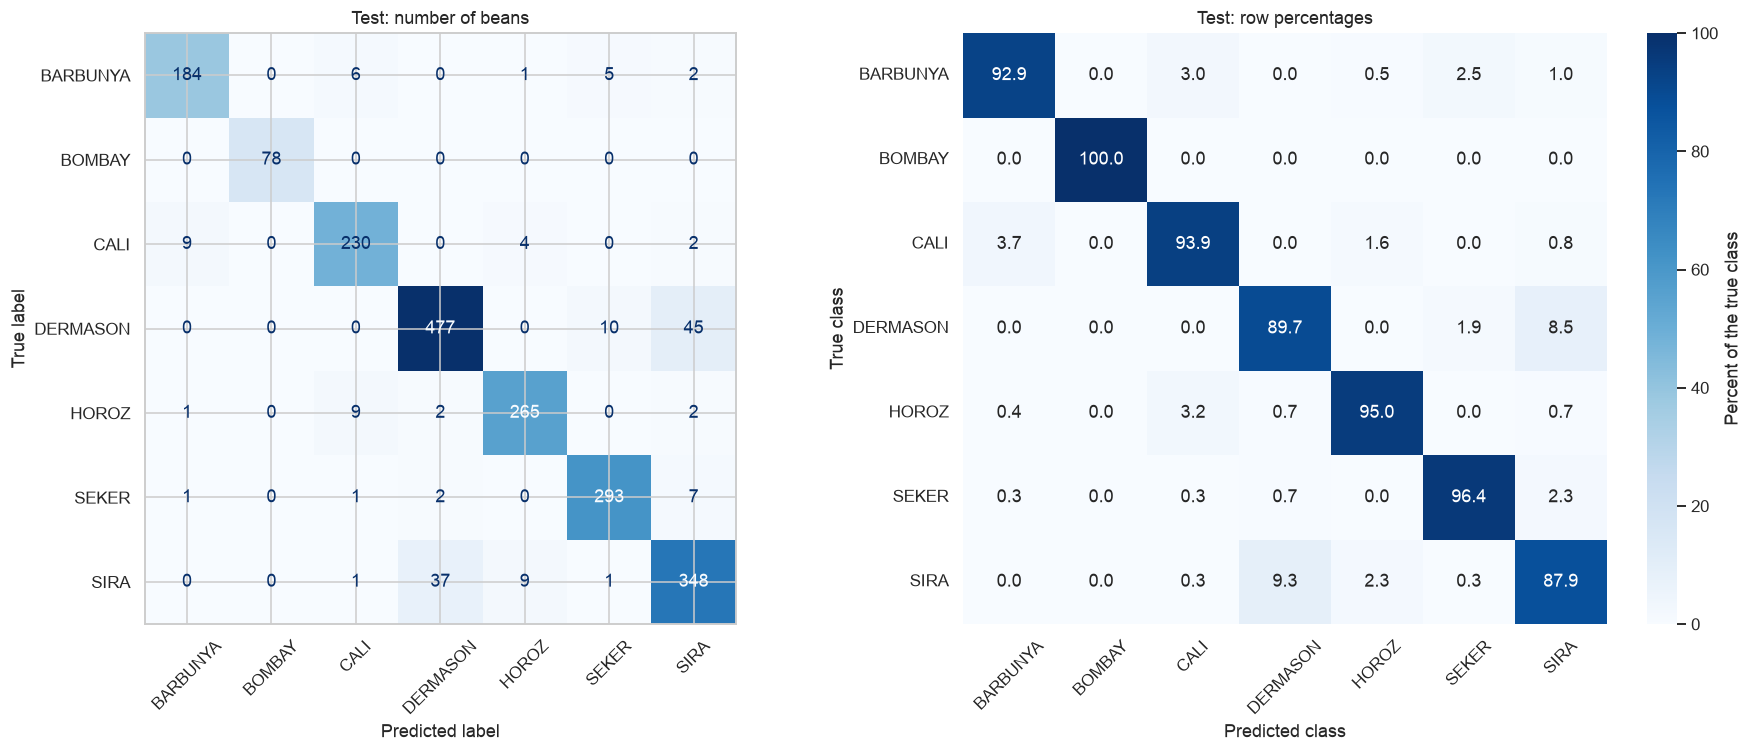

**Result:** Highest recall: **BOMBAY (78/78 correct)**, at **100.00%**. Lowest recall: **SIRA**, at **87.88%** (348/396 correct).

In [21]:
cm = confusion_matrix(y_test, test_predictions, labels=class_ids)
cm_percent = 100 * cm / cm.sum(axis=1, keepdims=True)
assert cm.sum() == len(y_test)
assert cm.trace() == correct_count

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45
)
axes[0].set_title("Test: number of beans")
sns.heatmap(cm_percent, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={"label": "Percent of the true class"}, ax=axes[1])
axes[1].set(title="Test: row percentages", xlabel="Predicted class", ylabel="True class")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

recalls = np.diag(cm) / cm.sum(axis=1)
best_recall_ids = np.flatnonzero(np.isclose(recalls, recalls.max()))
best_recall_text = ", ".join(
    f"{class_names[i]} ({cm[i, i]}/{cm[i].sum()} correct)" for i in best_recall_ids
)
lowest_recall_id = int(recalls.argmin())
say(
    f"**Result:** Highest recall: **{best_recall_text}**, at **{recalls.max():.2%}**. "
    f"Lowest recall: **{class_names[lowest_recall_id]}**, at "
    f"**{recalls[lowest_recall_id]:.2%}** "
    f"({cm[lowest_recall_id, lowest_recall_id]}/{cm[lowest_recall_id].sum()} correct)."
)

**What the output means:** The count matrix tells me how many beans are involved.
The row-percentage matrix tells me how often each true class is found.
Each diagonal percentage is that class's recall, not its precision.
A large count on the diagonal does not by itself prove that a class has the best recall.

## Step 22. Calculate one-vs-rest metrics by hand

I choose **BOMBAY**, as in the lab example.
All other types are temporarily called **not BOMBAY**.

1. TP is the BOMBAY diagonal cell.
2. FP is the rest of the BOMBAY column.
3. FN is the rest of the BOMBAY row.
4. Put the numbers into the precision, recall, and F1 formulas.
5. Check the result against the library report.

In [22]:
bombay_id = int(np.flatnonzero(class_names == "BOMBAY")[0])
tp = int(cm[bombay_id, bombay_id])
fp = int(cm[:, bombay_id].sum() - tp)
fn = int(cm[bombay_id, :].sum() - tp)
bombay_precision = tp / (tp + fp) if tp + fp else 0.0
bombay_recall = tp / (tp + fn) if tp + fn else 0.0
bombay_f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

say(
    f"**BOMBAY:** TP = **{tp}**, FP = **{fp}**, FN = **{fn}**.\n\n"
    f"Precision = {tp} / ({tp} + {fp}) = **{bombay_precision:.4f}**.\n\n"
    f"Recall = {tp} / ({tp} + {fn}) = **{bombay_recall:.4f}**.\n\n"
    f"F1 = 2 × {tp} / (2 × {tp} + {fp} + {fn}) = **{bombay_f1:.4f}**. "
    "This is the same F1 formula after replacing precision and recall with their fractions."
)
assert np.isclose(bombay_precision, test_report["BOMBAY"]["precision"])
assert np.isclose(bombay_recall, test_report["BOMBAY"]["recall"])
assert np.isclose(bombay_f1, test_report["BOMBAY"]["f1-score"])
print("The hand calculation and the report agree.")

**BOMBAY:** TP = **78**, FP = **0**, FN = **0**.

Precision = 78 / (78 + 0) = **1.0000**.

Recall = 78 / (78 + 0) = **1.0000**.

F1 = 2 × 78 / (2 × 78 + 0 + 0) = **1.0000**. This is the same F1 formula after replacing precision and recall with their fractions.

The hand calculation and the report agree.


**What the output means:** One-vs-rest lets me use binary class formulas inside a seven-class problem.
The same method works for any of the seven classes.
If a denominator is zero, this notebook reports 0 for that metric instead of stopping with an error.

## Step 23. Find the two classes most often confused with each other

I must count errors in **both directions**.

For each pair A and B:
- count true A predicted as B;
- count true B predicted as A;
- add the two counts.

I ignore the diagonal because it contains correct answers.
I list each pair only once and sort by total mistakes.

In [23]:
pair_rows = []
for i in range(len(class_names)):
    for j in range(i + 1, len(class_names)):
        pair_rows.append({
            "Class A": class_names[i],
            "Class B": class_names[j],
            "A predicted as B": int(cm[i, j]),
            "B predicted as A": int(cm[j, i]),
            "Mutual errors": int(cm[i, j] + cm[j, i]),
            "A ID": i,
            "B ID": j,
        })
pair_table = pd.DataFrame(pair_rows).sort_values(
    ["Mutual errors", "Class A", "Class B"], ascending=[False, True, True]
).reset_index(drop=True)
display(pair_table.drop(columns=["A ID", "B ID"]).head(5))
most_confused = pair_table.iloc[0]
pair_a = most_confused["Class A"]
pair_b = most_confused["Class B"]
pair_a_id = int(most_confused["A ID"])
pair_b_id = int(most_confused["B ID"])
mutual_errors = int(most_confused["Mutual errors"])
total_errors = len(y_test) - correct_count

say(
    f"**Most confused pair:** **{pair_a} and {pair_b}**.\n\n"
    f"- True {pair_a}, predicted {pair_b}: **{int(most_confused['A predicted as B'])}**.\n"
    f"- True {pair_b}, predicted {pair_a}: **{int(most_confused['B predicted as A'])}**.\n"
    f"- Total mutual errors: **{mutual_errors}**.\n\n"
    f"This pair accounts for **{mutual_errors / total_errors:.2%}** "
    f"of the **{total_errors}** test mistakes." if total_errors else "There are no test mistakes."
)

,Class A,Class B,A predicted as B,B predicted as A,Mutual errors
0,DERMASON,SIRA,45,37,82
1,BARBUNYA,CALI,6,9,15
2,CALI,HOROZ,4,9,13
3,DERMASON,SEKER,10,2,12
4,HOROZ,SIRA,2,9,11


**Most confused pair:** **DERMASON and SIRA**.

- True DERMASON, predicted SIRA: **45**.
- True SIRA, predicted DERMASON: **37**.
- Total mutual errors: **82**.

This pair accounts for **52.23%** of the **157** test mistakes.

**What the output means:** The hardest pair is chosen from the confusion matrix, not guessed from class names.
The total counts both directions. One direction can be more common than the other.
This is error analysis after final evaluation. I do not use it to change the selected model.

## Step 24. Compare three features for the difficult pair

I compare **Area**, **AspectRatio**, and **Compactness** for the two classes.

1. Keep test beans from these two true classes.
2. Show their medians and their middle 50% ranges.
3. Use the same histogram bins for both classes.
4. Use density on the vertical axis so groups of different sizes can be compared.
5. Check whether the middle 50% intervals overlap.

A **histogram** groups nearby values into bars.
**Density** makes the total bar area equal to 1 for each class.
The **middle 50% interval** is from the 25th percentile to the 75th percentile.

,Feature,Class,Beans,Mean,25%,Median,75%
0,Area,DERMASON,532,32386.0827,28544.5000,32204.5000,35846.2500
1,Area,SIRA,396,44929.2500,41709.2500,44907.5000,47768.0000
2,AspectRatio,DERMASON,532,1.4912,1.4294,1.4851,1.5509
3,AspectRatio,SIRA,396,1.5810,1.5139,1.5755,1.6400
4,Compactness,DERMASON,532,0.8189,0.8023,0.8193,0.8357
5,Compactness,SIRA,396,0.7947,0.7795,0.7947,0.8108


,Feature,Middle 50% intervals overlap,Overlap width
0,Area,False,0.0000
1,AspectRatio,True,0.0369
2,Compactness,True,0.0085


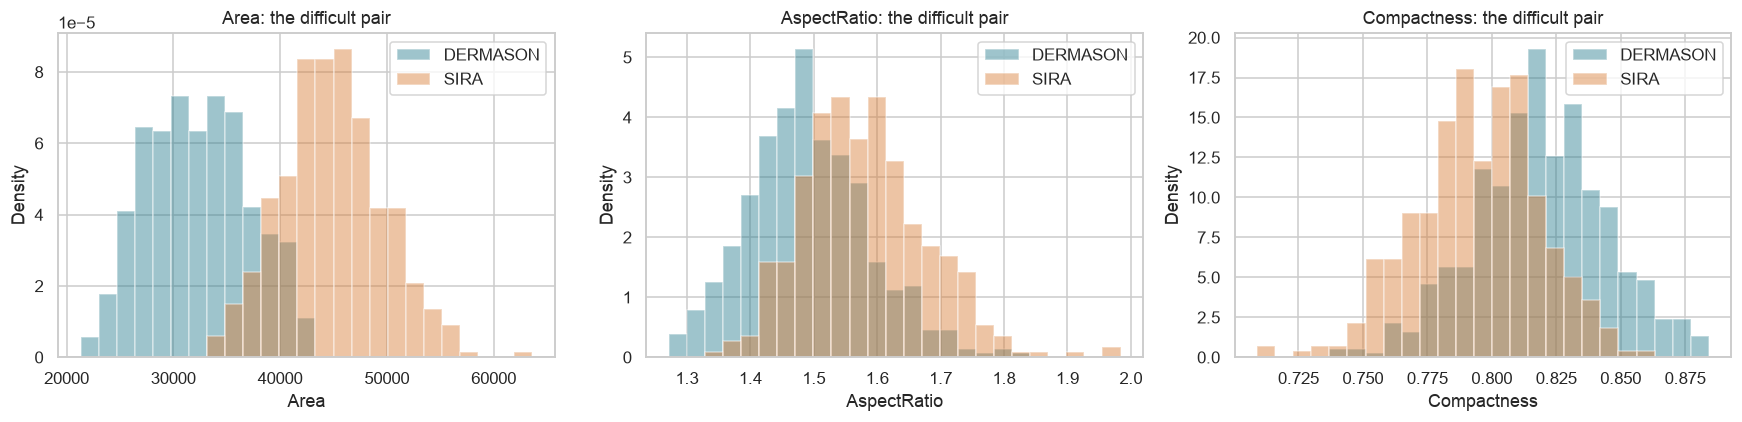

**Result:** The middle 50% intervals overlap for **AspectRatio, Compactness**.

For **Area**, the median is **32204.5000** for **DERMASON** and **44907.5000** for **SIRA**.

For **AspectRatio**, the median is **1.4851** for **DERMASON** and **1.5755** for **SIRA**.

For **Compactness**, the median is **0.8193** for **DERMASON** and **0.7947** for **SIRA**.

When beans from two classes have similar input numbers, one simple cutoff cannot separate them well. This overlap is a possible reason for mistakes. The network uses all 16 features together, so these three plots do not prove the full cause of every mistake.

In [24]:
test_frame = X_test.copy()
test_frame["Class"] = class_names[y_test]
pair_data = test_frame[test_frame["Class"].isin([pair_a, pair_b])].copy()

comparison_rows = []
overlap_rows = []
for feature in FEATURES_TO_PLOT:
    intervals = {}
    for name in [pair_a, pair_b]:
        values = pair_data.loc[pair_data["Class"] == name, feature]
        q25, median, q75 = values.quantile([0.25, 0.50, 0.75])
        intervals[name] = (q25, q75)
        comparison_rows.append({
            "Feature": feature, "Class": name, "Beans": len(values),
            "Mean": values.mean(), "25%": q25, "Median": median, "75%": q75,
        })
    left = max(intervals[pair_a][0], intervals[pair_b][0])
    right = min(intervals[pair_a][1], intervals[pair_b][1])
    overlap_rows.append({
        "Feature": feature,
        "Middle 50% intervals overlap": bool(right >= left),
        "Overlap width": max(0.0, right - left),
    })

pair_feature_table = pd.DataFrame(comparison_rows)
overlap_table = pd.DataFrame(overlap_rows)
display(pair_feature_table.round(4))
display(overlap_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, FEATURES_TO_PLOT):
    bins = np.histogram_bin_edges(pair_data[feature], bins=25)
    for name, color in [(pair_a, "#287c8e"), (pair_b, "#d97c36")]:
        values = pair_data.loc[pair_data["Class"] == name, feature]
        ax.hist(values, bins=bins, density=True, alpha=0.45, label=name, color=color)
    ax.set(title=f"{feature}: the difficult pair", xlabel=feature, ylabel="Density")
    ax.legend()
plt.tight_layout()
plt.show()

overlapping_features = overlap_table.loc[
    overlap_table["Middle 50% intervals overlap"], "Feature"
].tolist()
say(
    f"**Result:** The middle 50% intervals overlap for "
    f"**{', '.join(overlapping_features) if overlapping_features else 'none of these three features'}**."
)
for feature in FEATURES_TO_PLOT:
    medians = pair_feature_table[pair_feature_table["Feature"] == feature].set_index("Class")["Median"]
    say(
        f"For **{feature}**, the median is **{medians[pair_a]:.4f}** for "
        f"**{pair_a}** and **{medians[pair_b]:.4f}** for **{pair_b}**."
    )
say(
    "When beans from two classes have similar input numbers, one simple cutoff cannot separate them well. "
    "This overlap is a possible reason for mistakes. The network uses all 16 features together, "
    "so these three plots do not prove the full cause of every mistake."
)

**What the output means:** Different class medians do not mean every bean is easy to separate.
The ranges around the medians matter too.
Even when middle 50% intervals do not overlap, outer parts of the distributions can still overlap.
I use both the table and the histograms. This analysis describes the frozen model's errors; it does not start new tuning.

# Part 4. Conclusions

## Step 25. Answer the ten lab questions

The answers below use the actual results from this run.
The code only puts those results into short English sentences. It does not train another model.

In [25]:
scaling_direction = "increases" if scaling_gain > 0 else "decreases" if scaling_gain < 0 else "does not change"
size_direction = "rises" if data_size_gain > 0 else "falls" if data_size_gain < 0 else "stays the same"

say(f'''
### 1. Why is this supervised learning?

Each training bean has 16 input numbers and a correct class name.
The network learns from examples with known answers. This is supervised learning.

### 2. Why are seven output neurons used?

There are seven bean classes. Each output gives a score that becomes the probability of one class.
One bean belongs to one of these classes.

### 3. Why is Softmax suitable for the output layer?

Softmax gives seven probabilities between 0 and 1. They add up to 1.
I choose the class with the largest probability. This fits a task with one correct class per bean.

### 4. What does the loss function measure?

Cross-entropy checks how much probability the network gives to the true class.
A higher probability for the true class gives a lower loss.
The final test loss is **{test_loss:.4f}**.

### 5. What is the role of backpropagation?

Backpropagation finds how the loss changes when each weight or bias changes.
These values are gradients. Adam uses them to update the parameters.
Backpropagation calculates the gradients; Adam makes the updates.

### 6. Did feature scaling affect training? Why?

Scaling {scaling_direction} validation accuracy from **{unscaled_run['validation_accuracy']:.2%}**
to **{scaled_run['validation_accuracy']:.2%}**.
Validation loss changes from **{unscaled_run['validation_loss']:.4f}**
to **{scaled_run['validation_loss']:.4f}**.
The raw features have very different sizes. Scaling makes their sizes more similar and changes how the network learns.
The learning curves show the effect across all 100 epochs.

### 7. Did a larger network always perform better?

{size_conclusion}
I select **{selected_name}** using validation macro F1, not the number of parameters.
Its validation macro F1 is **{selected_run['validation_macro_f1']:.4f}**.

### 8. Which two classes were confused most often?

The pair is **{pair_a} and {pair_b}**, with **{mutual_errors}** mutual test errors.
There are **{int(most_confused['A predicted as B'])}** errors from {pair_a} to {pair_b}
and **{int(most_confused['B predicted as A'])}** in the other direction.
Their feature plots show why some beans can be hard to separate.

### 9. Which metric is more informative than accuracy here, and why?

**Macro F1** is useful because the class sizes are different.
It gives each of the seven classes the same importance and uses both precision and recall.
Test accuracy is **{test_accuracy:.2%}**, and test macro F1 is **{test_macro_f1:.4f}**.
I also read the confusion matrix and each class's scores.

### 10. What did I learn from the creative experiment?

From 20% to 100% of training data, validation macro F1 {size_direction}
from **{first_size['Validation macro F1']:.4f}** to **{last_size['Validation macro F1']:.4f}**.
The best observed score is at **{int(best_size['Requested train share (%)'])}%**.
More examples can help the network see more patterns, but each small increase in data may not improve the score.
One split and one seed are not enough to find a universal minimum dataset size.
''')


### 1. Why is this supervised learning?

Each training bean has 16 input numbers and a correct class name.
The network learns from examples with known answers. This is supervised learning.

### 2. Why are seven output neurons used?

There are seven bean classes. Each output gives a score that becomes the probability of one class.
One bean belongs to one of these classes.

### 3. Why is Softmax suitable for the output layer?

Softmax gives seven probabilities between 0 and 1. They add up to 1.
I choose the class with the largest probability. This fits a task with one correct class per bean.

### 4. What does the loss function measure?

Cross-entropy checks how much probability the network gives to the true class.
A higher probability for the true class gives a lower loss.
The final test loss is **0.2052**.

### 5. What is the role of backpropagation?

Backpropagation finds how the loss changes when each weight or bias changes.
These values are gradients. Adam uses them to update the parameters.
Backpropagation calculates the gradients; Adam makes the updates.

### 6. Did feature scaling affect training? Why?

Scaling increases validation accuracy from **63.27%**
to **92.27%**.
Validation loss changes from **2.5174**
to **0.2082**.
The raw features have very different sizes. Scaling makes their sizes more similar and changes how the network learns.
The learning curves show the effect across all 100 epochs.

### 7. Did a larger network always perform better?

A larger network is not always better in this run. At least one increase in size does not improve validation macro F1.
I select **Small** using validation macro F1, not the number of parameters.
Its validation macro F1 is **0.9375**.

### 8. Which two classes were confused most often?

The pair is **DERMASON and SIRA**, with **82** mutual test errors.
There are **45** errors from DERMASON to SIRA
and **37** in the other direction.
Their feature plots show why some beans can be hard to separate.

### 9. Which metric is more informative than accuracy here, and why?

**Macro F1** is useful because the class sizes are different.
It gives each of the seven classes the same importance and uses both precision and recall.
Test accuracy is **92.27%**, and test macro F1 is **0.9362**.
I also read the confusion matrix and each class's scores.

### 10. What did I learn from the creative experiment?

From 20% to 100% of training data, validation macro F1 rises
from **0.9223** to **0.9375**.
The best observed score is at **60%**.
More examples can help the network see more patterns, but each small increase in data may not improve the score.
One split and one seed are not enough to find a universal minimum dataset size.


**What the answers mean:** Each conclusion has a reason or a measured result.
I do not claim that the selected architecture is the best for every dataset or every random split.
This work shows what happened with the stated data, settings, and checks.

## Step 26. Check the work and show the final result

I make final checks without fitting another model:

1. The sets are separate and together contain all clean rows.
2. Each scaler used only its own training rows.
3. Every training history has 100 epochs.
4. Every saved epoch has the lowest validation loss in its run.
5. The saved network has the correct parameter count and a Softmax output.
6. The probability rows sum to 1.
7. The confusion matrix has one entry per test bean.
8. The hand-worked BOMBAY scores agree with the report.

In [26]:
all_runs = [unscaled_run, scaled_run, small_run, large_run] + [
    subset_runs[fraction] for fraction in fractions if fraction < 1.0
]
assert len(train_idx) + len(val_idx) + len(test_idx) == len(data)
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert not data.duplicated(subset=feature_names).any()
assert final_scaler.n_samples_seen_ == len(train_idx)

for run in all_runs:
    history = run["history"]
    assert len(history) == EPOCHS
    assert np.array_equal(history["Epoch"].to_numpy(), np.arange(1, EPOCHS + 1))
    assert np.isfinite(history.to_numpy()).all()
    assert run["best_epoch"] == int(history.loc[history["Validation loss"].idxmin(), "Epoch"])
    assert np.isclose(run["validation_loss"], history["Validation loss"].min())
    assert run["parameters"] == parameter_count(run["hidden_layers"])
    assert run["model"].out_activation_ == "softmax"

for fraction in fractions:
    assert subset_scalers[fraction].n_samples_seen_ == len(subset_positions[fraction])
    assert set(train_idx[subset_positions[fraction]]).isdisjoint(test_idx)
assert np.allclose(test_probabilities.sum(axis=1), 1.0, atol=1e-10)
assert cm.sum() == len(y_test) and cm.trace() == correct_count
assert np.isclose(bombay_f1, test_report["BOMBAY"]["f1-score"])
assert final_model is selected_run["model"]
assert subset_runs[1.0] is selected_run

print("All checks passed.")
say(f'''
### Final result

I train a neural network to classify beans from 16 size and shape features.
I remove **{duplicate_count}** repeated rows and keep **{len(data):,}** beans.
I compare scaling, three architectures, and five training-set sizes.

My selected network is **{' → '.join(map(str, (16,) + selected_hidden_layers + (7,)))}**.
It has **{selected_run['parameters']:,}** trainable parameters.
I use the saved model from epoch **{selected_run['best_epoch']}**.

On **{len(y_test):,}** test beans, accuracy is **{test_accuracy:.2%}**
and macro F1 is **{test_macro_f1:.4f}**.
The most confused pair is **{pair_a} and {pair_b}**.

### Limits of this work

- I use one train/validation/test split and one seed.
- I compare three architectures, not all possible networks.
- The data-size experiment uses the same epoch count, so larger sets have more updates.
- The results describe this dataset. New bean images or new measuring tools may give different results.
- Error plots help explain possible reasons for mistakes. They do not prove the full cause.

### Files and source

The full solution, figures, tables, and explanations are in this notebook.
The original rows are saved in **data/dry_bean.csv**.

Source: [Dry Bean Dataset, UCI, 2020](https://archive.ics.uci.edu/dataset/602/dry%2Bbean%2Bdataset).
DOI: [10.24432/C50S4B](https://doi.org/10.24432/C50S4B).
License: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
''')

All checks passed.



### Final result

I train a neural network to classify beans from 16 size and shape features.
I remove **68** repeated rows and keep **13,543** beans.
I compare scaling, three architectures, and five training-set sizes.

My selected network is **16 → 24 → 7**.
It has **583** trainable parameters.
I use the saved model from epoch **82**.

On **2,032** test beans, accuracy is **92.27%**
and macro F1 is **0.9362**.
The most confused pair is **DERMASON and SIRA**.

### Limits of this work

- I use one train/validation/test split and one seed.
- I compare three architectures, not all possible networks.
- The data-size experiment uses the same epoch count, so larger sets have more updates.
- The results describe this dataset. New bean images or new measuring tools may give different results.
- Error plots help explain possible reasons for mistakes. They do not prove the full cause.

### Files and source

The full solution, figures, tables, and explanations are in this notebook.
The original rows are saved in **data/dry_bean.csv**.

Source: [Dry Bean Dataset, UCI, 2020](https://archive.ics.uci.edu/dataset/602/dry%2Bbean%2Bdataset).
DOI: [10.24432/C50S4B](https://doi.org/10.24432/C50S4B).
License: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).


**End of the lab.** The results above come from the executed cells.
To repeat the work, restart the kernel and run all cells in order.